# 02 · ¿Cuánto le costó a un piloto su estrategia de gomas?

Este notebook mide **cuánto se gasta cada compuesto** en el Gran Premio de España 2024, una carrera seca, sin safety car ni banderas rojas, en la que se usaron blanda, media y dura (la eligió `scripts/buscar_carrera_gomas.py` entre las 89 carreras de 2023 a 2026).

Los datos vienen de [OpenF1](https://openf1.org). La limpieza vive en `f1analytics.datos.limpieza` y el análisis en `f1analytics.analisis.gomas`; aquí solo se usan y se dibujan.

> **Qué significa «degradación» aquí.** Es la pendiente de una recta que ajusta el tiempo de vuelta contra la edad de la goma dentro de un stint. No es el desgaste real de la goma: también se mezclan el tráfico, la temperatura de la pista y que el asfalto mejora con el paso de los coches, y con estos datos no se pueden separar. Una vuelta más lenta no prueba por sí sola que la goma esté gastada.

> Necesita internet y que no haya una sesión de F1 en vivo.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from f1analytics.analisis.gomas import (
    comparar_compuestos,
    degradacion_por_stint,
    resumen_gomas,
)
from f1analytics.datos.cargador import Cargador
from f1analytics.datos.cliente import ClienteOpenF1
from f1analytics.datos.limpieza import (
    agregar_correccion_combustible,
    agregar_edad_goma,
    estado_pista_por_vuelta,
    limpiar_vueltas_carrera,
)
from f1analytics.graficos.estilo import aplicar_estilo
from f1analytics.graficos.gomas import degradacion_compuestos, dispersion_edad, estrategias

aplicar_estilo()
pd.options.display.float_format = "{:,.3f}".format
CARPETA_FIGURAS = Path("../../docs/figuras")  # las figuras del README

cargador = Cargador(ClienteOpenF1())

## 1. La carrera

Se busca el Gran Premio de España de 2024 y se bajan sus vueltas, stints, paradas, la dirección de carrera y el resultado final.

In [2]:
ANIO = 2024
calendario = cargador.calendario(ANIO)
evento = int(calendario.loc[calendario["nombre"] == "Spanish Grand Prix", "evento"].iloc[0])
sesion = cargador.buscar_sesion(ANIO, evento, "Race")

vueltas = cargador.vueltas(sesion)
stints = cargador.stints(sesion)
paradas = cargador.paradas(sesion)
resultado = cargador.resultado(sesion)
pilotos = cargador.pilotos(sesion)
codigos = pilotos.set_index("numero")["codigo"]
n_vueltas = int(vueltas["vuelta"].max())

estado = estado_pista_por_vuelta(cargador.direccion_carrera(sesion), n_vueltas)
print(f"Sesión {sesion}: {n_vueltas} vueltas, {vueltas['piloto'].nunique()} pilotos")
print("Estado de la pista:", estado.value_counts().to_dict())

Sesión 9539: 66 vueltas, 20 pilotos
Estado de la pista: {'verde': 66}


## 2. Las estrategias

Una fila por piloto, ordenadas por posición final. Cada barra es un stint, con su compuesto (B blanda, M media, D dura) y las vueltas que duró.

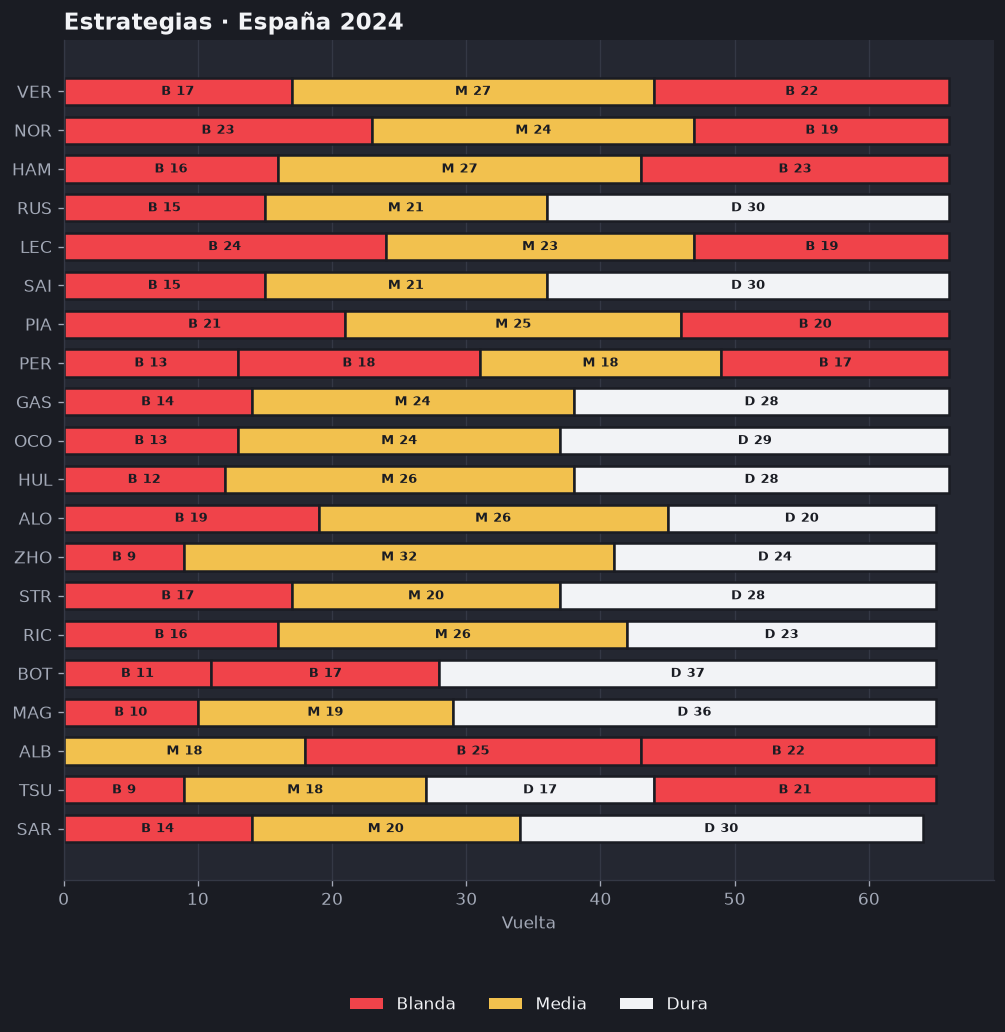

In [3]:
fig = estrategias(stints, resultado, pilotos, titulo="Estrategias · España 2024")
fig.savefig(CARPETA_FIGURAS / "gomas-estrategias.png", bbox_inches="tight")
plt.show()

## 3. Qué vueltas sirven

Para medir el desgaste hay que quitar las vueltas que no cuentan. Se aplican los filtros uno tras otro y se ve cuántas vueltas quedan:

1. Solo las que tienen tiempo.
2. Sin la vuelta 1 (arranque parado con la parrilla llena).
3. Sin la entrada y la salida de boxes.
4. Sin las vueltas con safety car, VSC o bandera roja o amarilla en pista (en esta carrera no hay ninguna).
5. Sin las vueltas más de un 7 % más lentas que la mediana del piloto (tráfico, errores).

In [4]:
TODO_APAGADO = dict(quitar_primera=False, solo_verde=False, quitar_pits=False, umbral_mediana=None)
pasos = [
    ("Con tiempo", TODO_APAGADO),
    ("Sin la vuelta 1", {**TODO_APAGADO, "quitar_primera": True}),
    ("Sin boxes", {**TODO_APAGADO, "quitar_primera": True, "quitar_pits": True}),
    (
        "Solo bandera verde",
        {**TODO_APAGADO, "quitar_primera": True, "quitar_pits": True, "solo_verde": True},
    ),
    ("Sin las muy lentas", {}),  # los valores por defecto aplican todos los filtros
]
cuentas = pd.Series(
    {
        nombre: len(limpiar_vueltas_carrera(vueltas, paradas, estado, **filtros))
        for nombre, filtros in pasos
    },
    name="vueltas",
)
print(f"Vueltas totales de la carrera: {len(vueltas)}")
cuentas.to_frame()

Vueltas totales de la carrera: 1310


,vueltas
Con tiempo,1309
Sin la vuelta 1,1290
Sin boxes,1206
Solo bandera verde,1206
Sin las muy lentas,1205


In [5]:
limpias = limpiar_vueltas_carrera(vueltas, paradas, estado)
limpias = agregar_edad_goma(limpias, stints)
limpias = agregar_correccion_combustible(limpias)
columnas = ["piloto", "vuelta", "compuesto", "edad_goma", "tiempo_vuelta_s", "tiempo_corregido_s"]
limpias[columnas].head()

,piloto,vuelta,compuesto,edad_goma,tiempo_vuelta_s,tiempo_corregido_s
0,1,2,SOFT,4,79.871,79.931
1,1,3,SOFT,5,79.364,79.484
2,1,4,SOFT,6,80.766,80.946
3,1,5,SOFT,7,80.827,81.067
4,1,6,SOFT,8,80.876,81.176


## 4. Por qué se corrige el combustible

El coche sale con unos 100 kg de combustible y termina casi vacío: cada vuelta pesa menos y es más rápida, **aunque la goma se gaste**. Si no se corrige, el desgaste parece menor de lo que es. Aquí se suma a cada vuelta lo que ganó por ser más ligero (0,06 s por vuelta, una aproximación) y se compara la pendiente con y sin esa corrección.

In [6]:
sin_corregir = comparar_compuestos(degradacion_por_stint(limpias, "tiempo_vuelta_s"))
corregida = comparar_compuestos(degradacion_por_stint(limpias, "tiempo_corregido_s"))

comparacion = sin_corregir[["compuesto", "pendiente_s_por_vuelta"]].merge(
    corregida[["compuesto", "pendiente_s_por_vuelta", "n_stints", "n_vueltas"]],
    on="compuesto",
    suffixes=("_sin_corregir", "_corregida"),
)
comparacion

,compuesto,pendiente_s_por_vuelta_sin_corregir,pendiente_s_por_vuelta_corregida,n_stints,n_vueltas
0,SOFT,0.039,0.099,30,458
1,MEDIUM,0.029,0.089,19,401
2,HARD,0.025,0.085,13,346


## 5. Tiempo contra edad de la goma

Los tres primeros de la carrera. Cada punto es una vuelta limpia, el color es el compuesto y el marcador, el piloto. Las rectas son el ajuste de cada stint: cuanto más inclinada, más se gasta la goma.

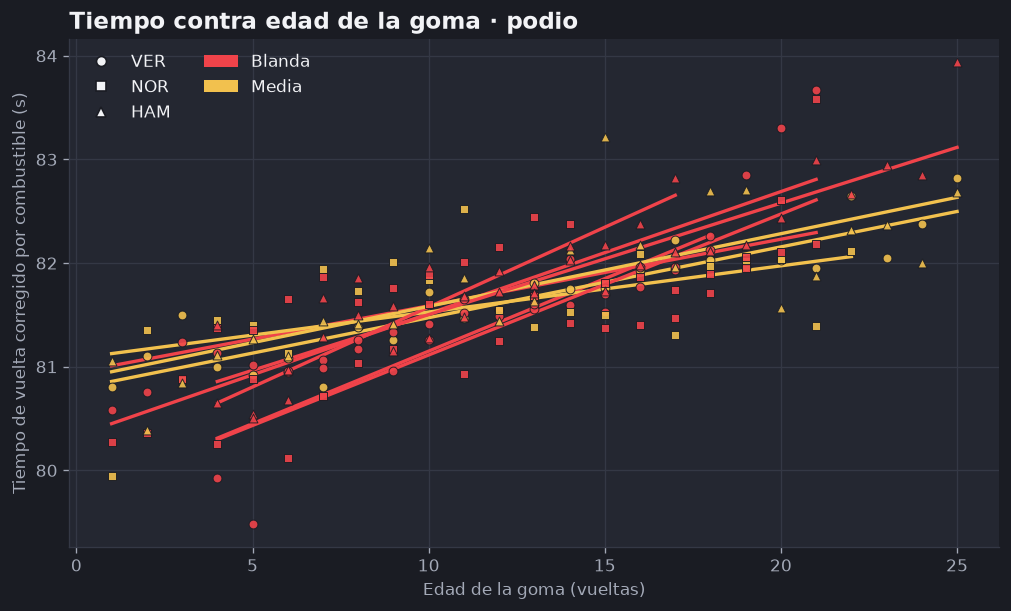

In [7]:
degradacion = degradacion_por_stint(limpias)
podio = [int(p) for p in resultado["piloto"].head(3)]
fig = dispersion_edad(
    limpias, degradacion, podio, codigos, titulo="Tiempo contra edad de la goma · podio"
)
fig.savefig(CARPETA_FIGURAS / "gomas-dispersion.png", bbox_inches="tight")
plt.show()

## 6. Degradación por compuesto

El promedio de todos los stints de cada compuesto, ponderado por sus vueltas (un stint largo pesa más que uno corto). Los stints con menos de 5 vueltas limpias no cuentan.

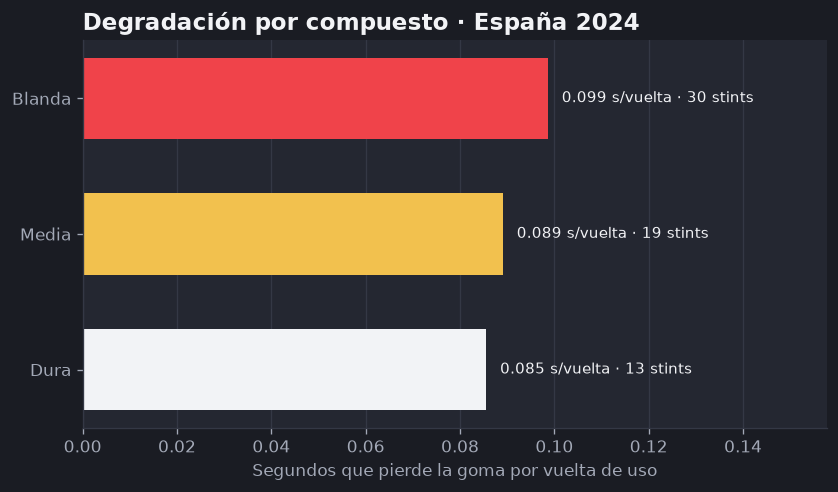

,compuesto,n_stints,n_vueltas,pendiente_s_por_vuelta,mediana
0,SOFT,30,458,0.099,0.105
1,MEDIUM,19,401,0.089,0.082
2,HARD,13,346,0.085,0.078


In [8]:
por_compuesto = comparar_compuestos(degradacion)
fig = degradacion_compuestos(por_compuesto, titulo="Degradación por compuesto · España 2024")
fig.savefig(CARPETA_FIGURAS / "gomas-degradacion.png", bbox_inches="tight")
plt.show()
por_compuesto

In [9]:
por_stint = degradacion.assign(piloto=lambda t: t["piloto"].map(codigos))
columnas = ["piloto", "stint", "compuesto", "n_vueltas", "edad_inicial", "edad_final"]
por_stint[[*columnas, "pendiente_s_por_vuelta", "r2"]]

,piloto,stint,compuesto,n_vueltas,edad_inicial,edad_final,pendiente_s_por_vuelta,r2
0,VER,1,SOFT,15,4,18,0.140,0.736
1,VER,2,MEDIUM,25,1,25,0.068,0.834
2,VER,3,SOFT,21,1,21,0.118,0.801
3,SAR,1,SOFT,12,1,12,0.031,0.068
4,SAR,2,MEDIUM,18,1,18,0.170,0.885
...,...,...,...,...,...,...,...,...
57,BOT,2,SOFT,15,4,18,0.273,0.906
58,BOT,3,HARD,36,1,36,0.070,0.355
59,PIA,1,SOFT,19,4,22,0.103,0.776
60,PIA,2,MEDIUM,23,1,23,0.059,0.610


## 7. Conclusión

`resumen_gomas` devuelve solo datos; la web los convierte en una frase en español o en inglés. Aquí se arma una a mano, con sus límites.

In [10]:
resumen = resumen_gomas(degradacion, stints)
mas, menos = resumen["compuesto_mas_degradante"], resumen["compuesto_menos_degradante"]
largo = resumen["stint_mas_largo"]
validos, pocos = resumen["n_stints_validos"], resumen["n_stints_insuficientes"]
print(f"{validos} stints con pendiente, {pocos} con muy pocas vueltas.")
print(f"La que más se gasta: {mas['compuesto']} ({mas['pendiente_s_por_vuelta']:.3f} s/vuelta).")
print(f"La que menos: {menos['compuesto']} ({menos['pendiente_s_por_vuelta']:.3f} s/vuelta).")
piloto_largo = codigos[largo["piloto"]]
print(f"Stint más largo: {piloto_largo} con la {largo['compuesto']}, {largo['vueltas']} vueltas.")
print(f"Paradas por piloto: {resumen['paradas_por_piloto']:.1f}.")
print(f"Stints sin degradación medible (pendiente ≤ 0): {resumen['n_stints_sin_degradacion']}.")
resumen

62 stints con pendiente, 0 con muy pocas vueltas.
La que más se gasta: SOFT (0.099 s/vuelta).
La que menos: HARD (0.085 s/vuelta).
Stint más largo: BOT con la HARD, 37 vueltas.
Paradas por piloto: 2.1.
Stints sin degradación medible (pendiente ≤ 0): 3.


{'n_stints_validos': 62,
 'n_stints_insuficientes': 0,
 'n_stints_sin_degradacion': 3,
 'compuesto_mas_degradante': {'compuesto': 'SOFT',
  'pendiente_s_por_vuelta': 0.0985757729101363},
 'compuesto_menos_degradante': {'compuesto': 'HARD',
  'pendiente_s_por_vuelta': 0.08549354704241446},
 'stint_mas_largo': {'piloto': 77, 'compuesto': 'HARD', 'vueltas': 37},
 'paradas_por_piloto': 2.1}

### Lo que este análisis no puede decir

- **El tráfico:** un piloto que va detrás de otro pierde tiempo sin que la goma tenga nada que ver.
- **La temperatura y el asfalto:** la pista cambia durante la carrera y eso se mezcla con la edad de la goma.
- **El combustible:** la corrección de 0,06 s por vuelta es una aproximación; con otro valor las pendientes suben o bajan todas por igual, pero las comparaciones entre compuestos se mantienen.
- **La edad de las gomas usadas:** las gomas de clasificación que traen algunas vueltas ya hechas cuentan esa edad, pero no cuánto se exigieron.